# Julia notebook to compute the plot the expression $G_{ \mathfrak{u}, b} (z; \xi')$, which is computed in `ComputeQuadratures.ipynb` and tested in `SymbolicsTesting.jl`
twnh 

Aug '26.  

This notebook reads the output from `ComputeQuadratures.ipynb` and makes a plot of this $G_{ \mathfrak{u}, b} (z; \xi')$ function, where

\begin{align}
G_{ \mathfrak{u}, b} (z; \xi') & = 
\int_{-H}^{0} G_{ \mathfrak{u}} (z; \xi) \, \int_{\xi}^{0}  G_b(z'; \xi') \; dz'  \; d \xi .
\end{align}

In [1]:
using SymPy
using Symbolics
using JLD2
using RuntimeGeneratedFunctions
RuntimeGeneratedFunctions.init(@__MODULE__)

#### Load and build callable `Symbolics` function for G_uvb

In [4]:
@variables x y z ξ ξp
@variables H
@variables Ek κ ν ψ φ

@load "symexpr.jld2" symbolics_Guvb
tmp = eval(build_function(symbolics_Guvb, H, ψ, ξp, φ, z, κ, ν; expression = Val(false)))
Guvb_expr_fun(H, z, ξp, φ, ψ, κ, ν) = tmp(H, ψ, ξp, φ, z, κ, ν)

println("Finished generating symbolic functions.")
println()

Finished generating symbolic functions.



#### Make plots

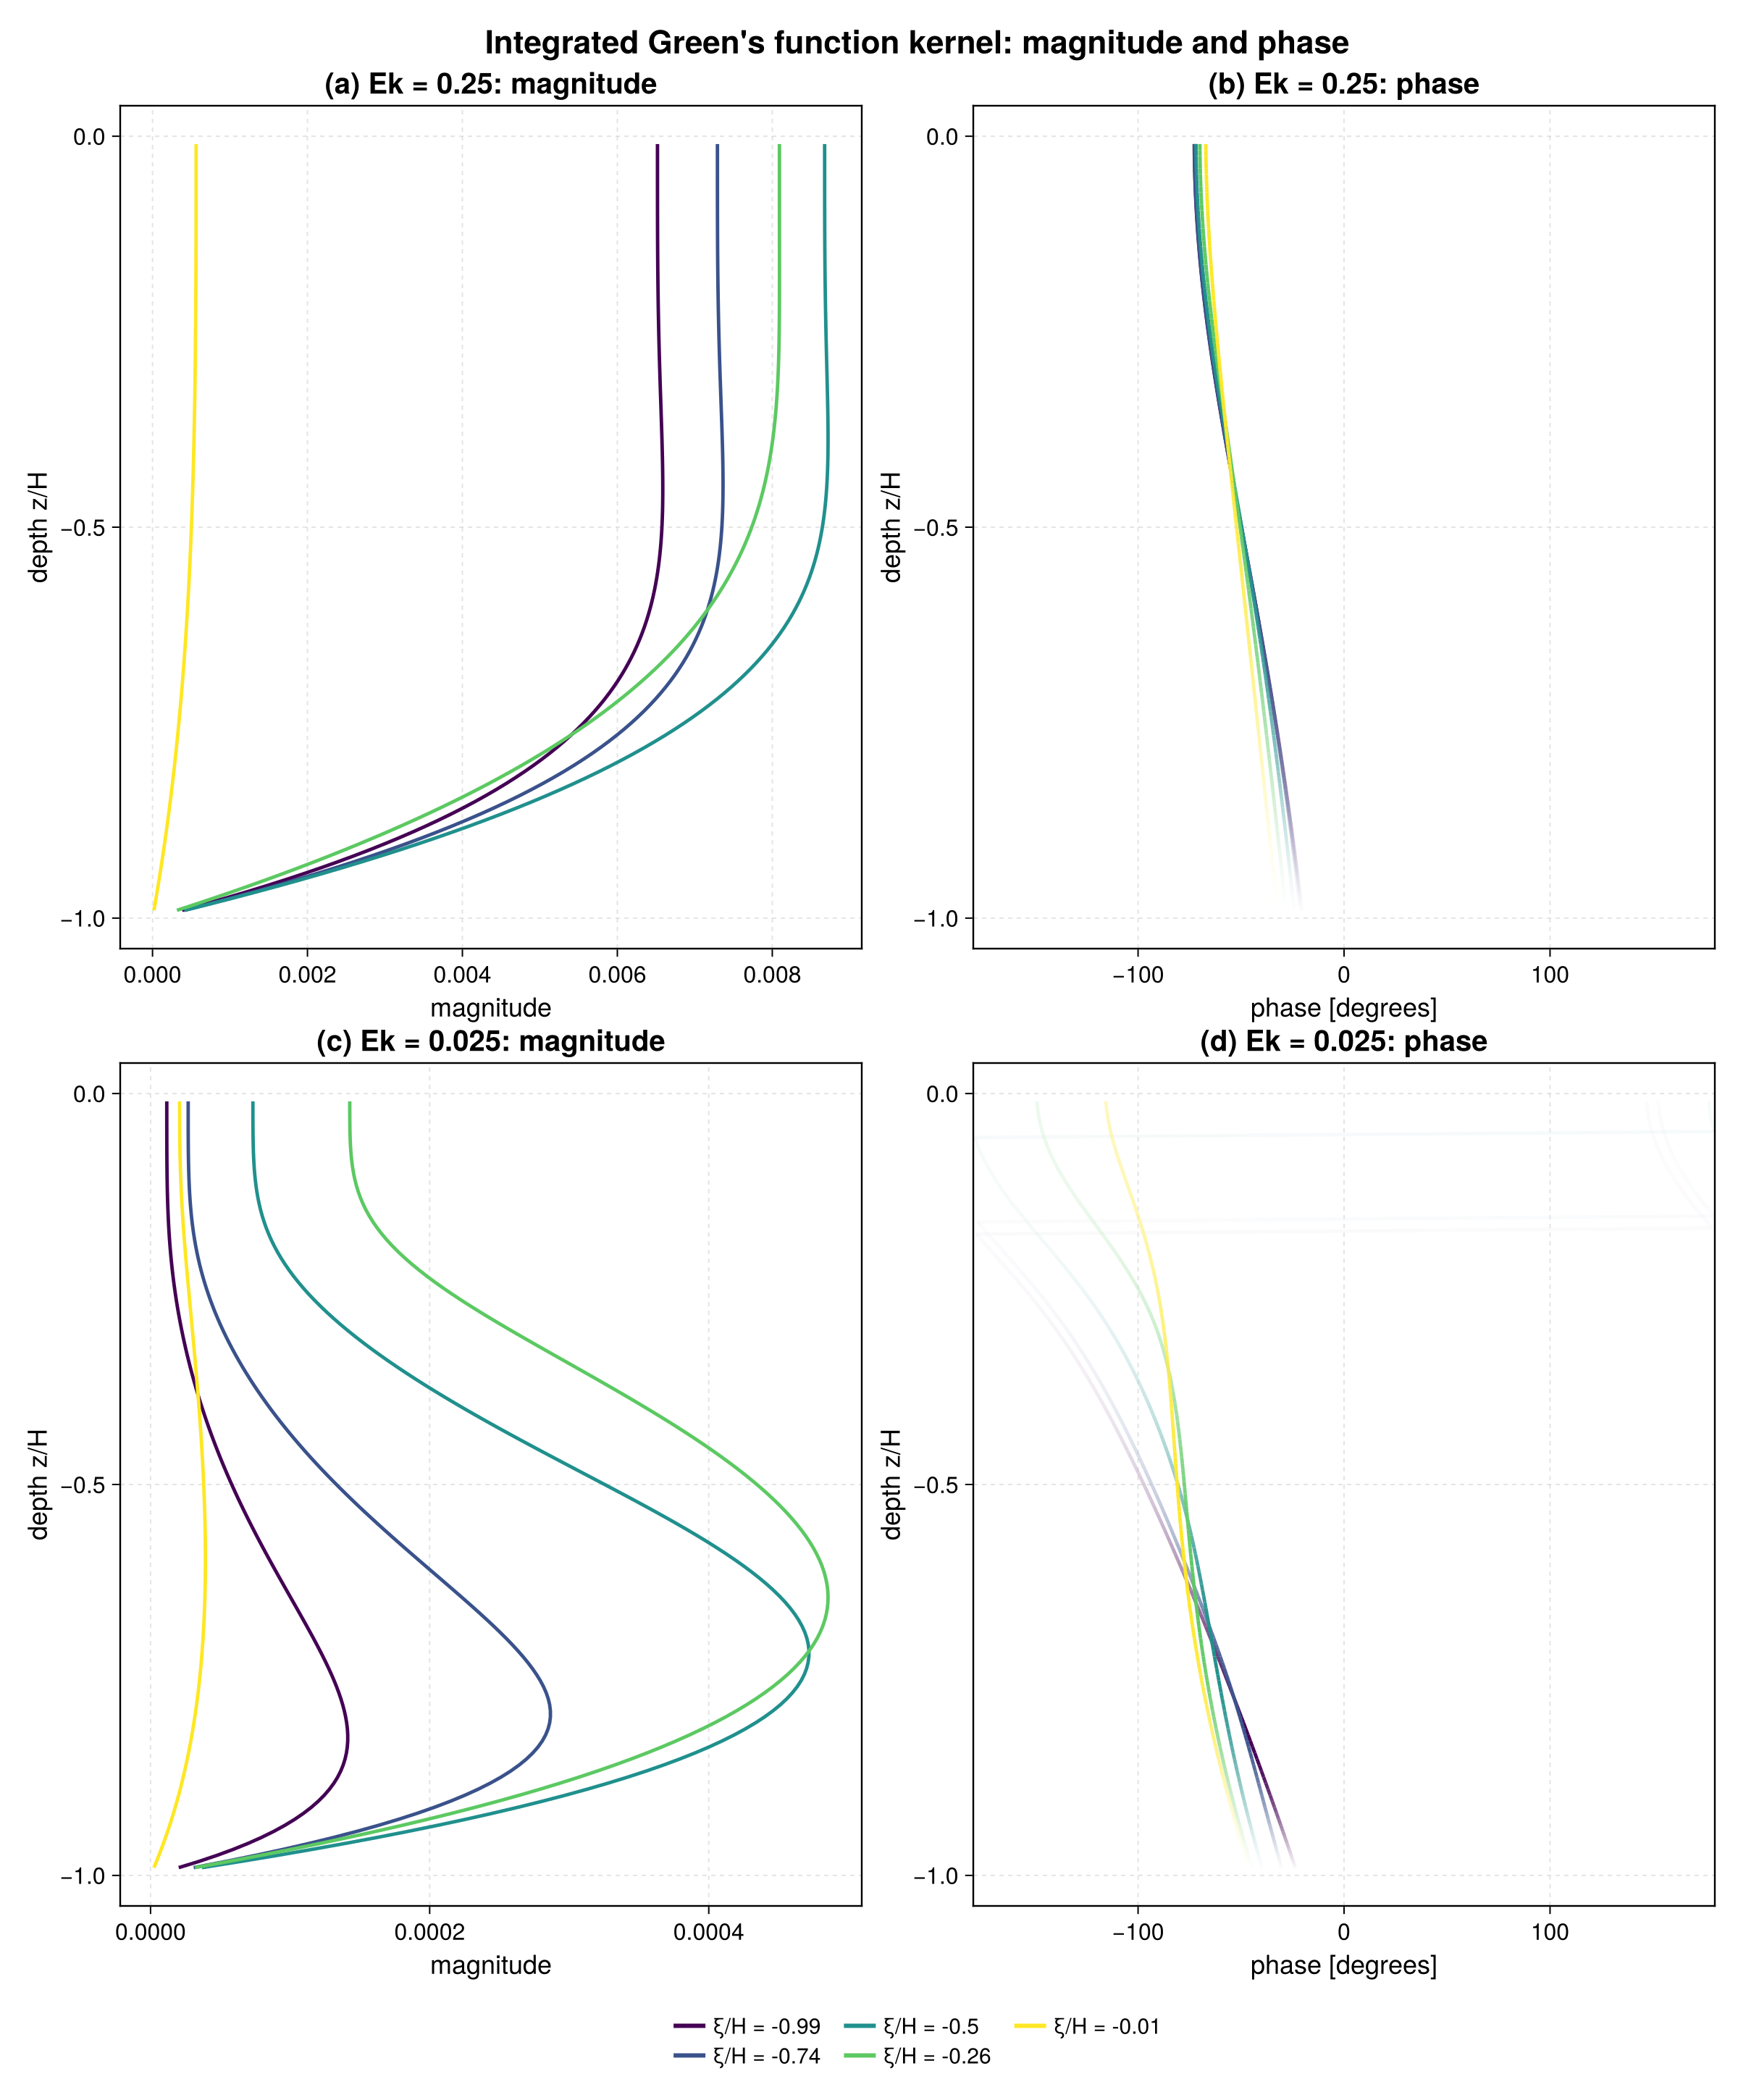

In [9]:
using CairoMakie
CairoMakie.activate!()

# -------------------------------------------------------------------
# Parameters
# -------------------------------------------------------------------
Hval = 1.0
Ek1 = 0.25
Ek2 = 0.025
Ek_vals = [Ek1, Ek2]
varϕ_vals = [sqrt(1im / Ek) for Ek in Ek_vals]
ψ_vals = [sqrt(1 / Ek) for Ek in Ek_vals]
zgrid = range(-Hval*0.99, -0.01, length=128)   # avoids undefined phase angle at z=-H
ξp_vals = range(-Hval*0.99, -0.01, length=5)

# Colors for ξ families
ξcols = cgrad(:viridis, length(ξp_vals), categorical=true)

# -------------------------------------------------------------------
# Publication-style theme
# -------------------------------------------------------------------
set_theme!(
    Theme(
        fontsize=16,
        fonts=(; regular="TeX Gyre Heros"),
        Axis=(
            titlesize=20,
            xlabelsize=18,
            ylabelsize=18,
            xticklabelsize=16,
            yticklabelsize=16,
            xgridvisible=true,
            ygridvisible=true,
            xgridstyle=:dash,
            ygridstyle=:dash,
            xgridcolor=(:gray70, 0.35),
            ygridcolor=(:gray70, 0.35),
            spinewidth=1.2,
            xticksize=5,
            yticksize=5,
            xminorticksvisible=false,
            yminorticksvisible=false,
            topspinevisible=true,
            rightspinevisible=true,
        ),
        Legend=(
            framevisible=false,
            labelsize=15,
            titlesize=16,
            patchsize=(22, 14),
        ),
        Lines=(
            linewidth=2.5,
        )
    )
)

# -------------------------------------------------------------------
# Styling helper
# -------------------------------------------------------------------
function style_axis!(ax)
    ax.topspinevisible = true
    ax.rightspinevisible = true
    ax.xgridvisible = true
    ax.ygridvisible = true
    ax.xgridstyle = :dash
    ax.ygridstyle = :dash
    ax.xgridcolor = (:gray70, 0.35)
    ax.ygridcolor = (:gray70, 0.35)
    return ax
end

# Colormap that fades from white to a given color
function fade_cmap(c)
    return cgrad([RGBAf(1, 1, 1, 0.12), c])
end

# -------------------------------------------------------------------
# Figure layout
# -------------------------------------------------------------------
fig = Figure(size=(1200, 1450))

Label(fig[0, 1:2],
    "Integrated Green's function kernel: magnitude and phase",
    fontsize=22,
    font=:bold
)

# -------------------------------------------------------------------
# Helper to plot one Ek row
# -------------------------------------------------------------------
function plot_ek_row!(fig, row, Ek, varϕ, ψ; Hval=Hval, zgrid=zgrid)

    if row ==  1
        panel_labels = ("(a) ", "(b) ")
    elseif row ==2
        panel_labels = ("(c) ", "(d) ")
    end # if

    ax_mag = Axis(fig[row, 1],
        xlabel="magnitude",
        ylabel="depth z/H",
        title="$(panel_labels[1])Ek = $(Ek): magnitude"
    )

    ax_ph = Axis(fig[row, 2],
        xlabel="phase [degrees]",
        ylabel="depth z/H",
        title="$(panel_labels[2])Ek = $(Ek): phase"
    )

    xlims!(ax_ph, -180, 180)

     # ----------------------------------------------------------------
    # G_uvb(z; ξp) family
    # ----------------------------------------------------------------
    for (j, ξp) in enumerate(ξp_vals)
        c = ξcols[j]
        Gvals = [Guvb_expr_fun(Hval, z, ξp, varϕ, ψ, 1.0, 1.0) for z in zgrid]

        mags = abs.(Gvals)
        phases = rad2deg.(angle.(Gvals))

        lines!(ax_mag, mags, zgrid,
            color=c,
            linewidth=2.4,
            label="G_u, ξ/H = $(round(ξp/Hval, digits=3))"
        )

        if isapprox(ξ, -H; atol=1e-12)
            phases = NaN .* phases
        end

        lines!(ax_ph, phases, zgrid,
            color=mags,
            colormap=fade_cmap(c),
            colorrange=(0, maximum(mags)),
            linewidth=2.4,
            label="G_u, ξ/H = $(round(ξp/Hval, digits=3))"
        )
    end

    return ax_mag, ax_ph
end

# -------------------------------------------------------------------
# Plot both Ek rows
# -------------------------------------------------------------------
ax11, ax12 = plot_ek_row!(fig, 1, Ek_vals[1], varϕ_vals[1], ψ_vals[1]; Hval=Hval)
ax21, ax22 = plot_ek_row!(fig, 2, Ek_vals[2], varϕ_vals[2], ψ_vals[2]; Hval=Hval)

# Link y axes
linkyaxes!(ax11, ax21)
linkyaxes!(ax12, ax22)

# -------------------------------------------------------------------
# Single shared legend below the panels
# -------------------------------------------------------------------
legend_elements = LineElement[]
legend_labels = String[]

for (j, ξp) in enumerate(ξp_vals)
    push!(legend_elements, LineElement(color=ξcols[j], linewidth=3))
    push!(legend_labels, "ξ/H = $(round(ξp/Hval, digits=2))")
end

legend_g = Legend(fig[3, 1:2],
    legend_elements,
    legend_labels,
    title="Green's function panel",
    orientation=:horizontal,
    nbanks=2,
    framevisible=false,
    tellwidth=false,
    halign=:center
)

# -------------------------------------------------------------------
# Tightened spacing
# -------------------------------------------------------------------
colgap!(fig.layout, 1, 10)
rowgap!(fig.layout, 1, 4)
rowgap!(fig.layout, 2, 2)

# -------------------------------------------------------------------
# Save to PDF
# -------------------------------------------------------------------
CairoMakie.save("Guvb_magnitude_phase_two_Ek.pdf", fig)

fig